# A2. PCA: Hidden Factor and Data Visualization

We will complete all six required parts of the assignment:

1. **A2.1:** Select 3–6 features describing the same aspect and explain the choice.
2. **A2.2:** Normalize the features, compute quadratic data scatter and SVD, and estimate the absolute and percentage contributions of all components.
3. **A2.3:** Visualize the first two components using range normalization and z-scoring, highlighting a selected group of observations.
4. **A2.4:** Interpret the first two components using their loadings.
5. **A2.5:** Apply conventional PCA, compare it with SVD under z-scoring, and justify the choice of normalization.
6. **A2.6:** Compute a hidden ranking factor and express both the factor and the features on a 0–100 scale.

Data source: Spotify Tracks Dataset (Kaggle). I use the shortened **pop-genre subset of 1000 tracks** created for Assignment 1 and saved as `spotify_pop_1000.csv`.

The file `spotify_pop_1000.csv` is loaded from the notebook directory.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('spotify_pop_1000.csv')
df

,track_name,artists,popularity,duration_ms,explicit,danceability,energy,loudness,valence,tempo,acousticness
0,Blinding Lights,The Weeknd,91,200040,False,0.514,0.730,-5.934,0.334,171.005,0.00146
1,Mann Mera,Gajendra Verma,74,200120,False,0.535,0.765,-7.862,0.373,191.827,0.05400
2,Summer High,AP Dhillon,83,177391,False,0.860,0.541,-6.510,0.952,114.984,0.16500
3,Under The Influence,Chris Brown,96,184613,True,0.733,0.690,-5.529,0.310,116.992,0.06350
4,Starboy,The Weeknd;Daft Punk,90,230453,True,0.679,0.587,-7.015,0.486,186.003,0.14100
...,...,...,...,...,...,...,...,...,...,...,...
995,Yathe Yathe,G. V. Prakash,64,344360,False,0.448,0.607,-4.606,0.484,139.509,0.79100
996,Annul Maelae,Harris Jayaraj;Sudha Ragunathan,64,322506,False,0.773,0.436,-10.972,0.533,115.917,0.67200
997,Tu Mile Dil Khile,Raj Barman,62,197716,False,0.639,0.368,-14.096,0.415,89.940,0.24500
998,Vaarayo Vaarayo,Harris Jayaraj;Unnikrishnan;Chinmayi;Mega,64,316680,False,0.718,0.361,-9.740,0.446,103.000,0.56500


## A2.1. Feature Selection

I selected five numerical audio features describing **how energetic and upbeat a track sounds**:

- **danceability:** how suitable the track is for dancing (0–1).
- **energy:** perceived intensity and activity of the track (0–1).
- **loudness:** average volume of the track in dB (negative values; closer to 0 means louder).
- **valence:** musical positiveness, from sad/dark (0) to happy/cheerful (1).
- **tempo:** speed of the track in beats per minute.

Together, these features describe a single aspect: the **energetic, upbeat character of the sound**. The correlation matrix (shown in A2.5) is consistent with this choice: energy, loudness, valence and danceability are positively related (for example, energy–loudness is 0.72), and tempo is weakly positive with energy and valence.

I did **not** include *acousticness*: it is the opposite pole of this aspect (correlation with energy is about −0.65), and the hidden ranking factor in A2.6 needs all features pointing in the same direction. *Popularity*, *duration* and *key* describe other aspects (success, length, music theory), so they are left out too.

The **explicit** feature (74 explicit tracks out of 1000) is used only to highlight a group in the visualizations and is excluded from the PCA calculations.

Note: some songs appear more than once in the file (same name and artist listed on different albums). I keep all 1000 rows, as in Assignment 1.

In [6]:
selected_features = ['danceability', 'energy', 'loudness', 'valence', 'tempo']
X = df[selected_features].to_numpy(dtype=float)
n, p = X.shape
explicit_group = df['explicit'].to_numpy(dtype=bool)

print("Selected features:", selected_features)
print(f"Observations: {n}, features: {p}")
print(f"Explicit tracks: {explicit_group.sum()}, non-explicit tracks: {(~explicit_group).sum()}")
print("Missing values in selected features:")
display(df[selected_features].isna().sum())
display(df[selected_features].head())

Selected features: ['danceability', 'energy', 'loudness', 'valence', 'tempo']
Observations: 1000, features: 5
Explicit tracks: 74, non-explicit tracks: 926
Missing values in selected features:


danceability    0
energy          0
loudness        0
valence         0
tempo           0
dtype: int64

,danceability,energy,loudness,valence,tempo
0,0.514,0.730,-5.934,0.334,171.005
1,0.535,0.765,-7.862,0.373,191.827
2,0.860,0.541,-6.510,0.952,114.984
3,0.733,0.690,-5.529,0.310,116.992
4,0.679,0.587,-7.015,0.486,186.003


## A2.2. Standardization, SVD, and Component Contributions

### Feature Normalization Before PCA

The features have different scales: tempo is measured in beats per minute (about 55–204),
loudness in negative decibels (about −21 to −1), while danceability, energy and valence lie between 0 and 1.
Without normalization, features with greater scatter (here, tempo) would dominate the principal components.

**1. Range Normalization**

Subtract the feature mean from each value and divide the result by the difference
between the maximum and minimum:

$$
x'_{ij} =
\frac{x_{ij} - \bar{x}_j}
{\max(x_j) - \min(x_j)}
$$

Here:

- $x_{ij}$ is the value of feature $j$ for observation $i$;
- $\bar{x}_j$ is the mean of feature $j$;
- $\max(x_j)-\min(x_j)$ is the range of feature $j$.

After transformation, each feature has a mean of 0 and a range of 1.
Values may be negative.

This method is sensitive to outliers because the range depends on the minimum and maximum.

**2. Standardization (Z-scoring)**

Subtract the feature mean from each value and divide the result by the standard deviation:

$$
z_{ij} = \frac{x_{ij} - \bar{x}_j}{\sigma_j}
$$

The mean and standard deviation are calculated as follows:

$$
\bar{x}_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij},
\qquad
\sigma_j =
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\bar{x}_j)^2}
$$

Here $n$ is the number of observations. Division by $n$ matches the calculation
used by `StandardScaler`.

In [7]:
# Range normalization
X_range = (X - X.mean(axis=0)) / (X.max(axis=0) - X.min(axis=0))

# Z-scoring
scaler_zscore = StandardScaler()
X_zscore = scaler_zscore.fit_transform(X)

In [8]:
# SVD compute

U_range, s_range, Vt_range = np.linalg.svd(X_range, full_matrices=False)

# Chose signs so that the largest absolute weight was positive.
for k in range(len(s_range)):
    if Vt_range[k, np.abs(Vt_range[k]).argmax()] < 0:
        U_range[:, k] *= -1
        Vt_range[k] *= -1

scatter_range = np.sum(X_range ** 2)
natural_range = s_range ** 2
percent_range = 100 * natural_range / scatter_range
pc_names = [f'PC{k + 1}' for k in range(p)]

svd_table_range = pd.DataFrame({
    'PC': pc_names,
    'singular_value': s_range,
    'natural_contribution': natural_range,
    'contribution_%': percent_range
})
svd_table_range[selected_features] = Vt_range

print(f"Total quadratic scatter: {scatter_range:.6f}")
print(f"Sum of absolute contributions: {natural_range.sum():.6f}")
print(f"Sum of percentage contributions: {percent_range.sum():.2f}%")
display(svd_table_range.round(3))

Total quadratic scatter: 191.452953
Sum of absolute contributions: 191.452953
Sum of percentage contributions: 100.00%


,PC,singular_value,natural_contribution,contribution_%,danceability,energy,loudness,valence,tempo
0,PC1,9.212,84.865,44.327,0.391,0.546,0.273,0.656,0.207
1,PC2,6.678,44.599,23.295,-0.406,0.066,0.015,-0.105,0.905
2,PC3,5.719,32.705,17.083,-0.314,0.660,0.434,-0.463,-0.251
3,PC4,4.790,22.947,11.986,0.762,0.061,-0.011,-0.586,0.269
4,PC5,2.517,6.337,3.310,0.051,-0.508,0.858,0.020,0.048


In [9]:
# SVD after z-scoring.

U_zscore, s_zscore, Vt_zscore = np.linalg.svd(X_zscore, full_matrices=False)

# Chose signs so that the largest absolute weight was positive.
for k in range(len(s_zscore)):
    if Vt_zscore[k, np.abs(Vt_zscore[k]).argmax()] < 0:
        U_zscore[:, k] *= -1
        Vt_zscore[k] *= -1

scatter_zscore = np.sum(X_zscore ** 2)
natural_zscore = s_zscore ** 2
percent_zscore = 100 * natural_zscore / scatter_zscore

svd_table_zscore = pd.DataFrame({
    'PC': pc_names,
    'singular_value': s_zscore,
    'natural_contribution': natural_zscore,
    'contribution_%': percent_zscore
})
svd_table_zscore[selected_features] = Vt_zscore

print(f"Total quadratic scatter: {scatter_zscore:.6f}")
print(f"Sum of absolute contributions: {natural_zscore.sum():.6f}")
print(f"Sum of percentage contributions: {percent_zscore.sum():.2f}%")
display(svd_table_zscore.round(6))


Total quadratic scatter: 5000.000000
Sum of absolute contributions: 5000.000000
Sum of percentage contributions: 100.00%


,PC,singular_value,natural_contribution,contribution_%,danceability,energy,loudness,valence,tempo
0,PC1,47.039619,2212.725722,44.254514,0.367731,0.582532,0.525820,0.473611,0.156960
1,PC2,32.599900,1062.753458,21.255069,-0.606840,0.167680,0.194586,-0.192115,0.727225
2,PC3,30.667342,940.485856,18.809717,0.347237,-0.282873,-0.498986,0.432548,0.602764
3,PC4,22.944780,526.462937,10.529259,-0.607348,-0.078909,-0.070355,0.737833,-0.274871
4,PC5,16.049051,257.572028,5.151441,-0.084102,0.739118,-0.657049,-0.085374,-0.087347


### Interpretation of Component Contributions

After **range normalization**, total quadratic scatter is **191.452953**. The five components account for **44.33%, 23.30%, 17.08%, 11.99%, and 3.31%** of this scatter (absolute contributions 84.865, 44.599, 32.705, 22.947, and 6.337).

After **z-scoring**, total scatter is **5000 = 1000 × 5**, since each standardized feature has a mean square of 1. The component contributions are **44.25%, 21.26%, 18.81%, 10.53%, and 5.15%** (absolute contributions 2212.726, 1062.753, 940.486, 526.463, and 257.572).

The absolute contributions of all components sum to the total scatter in both cases, and the percentages sum to 100%. The first component alone carries about 44% under both normalizations, and the first two together carry about two thirds. The last component is small (3–5%), which means the five features carry some redundancy: they are not five independent pieces of information.

These percentages refer to different normalized matrices, so percentages alone do not establish the superiority of either method.

## A2.3. Two-Dimensional Projections and the Selected Group

Two-dimensional contribution, range normalization: 67.62%
Two-dimensional contribution, z-scoring: 65.51%


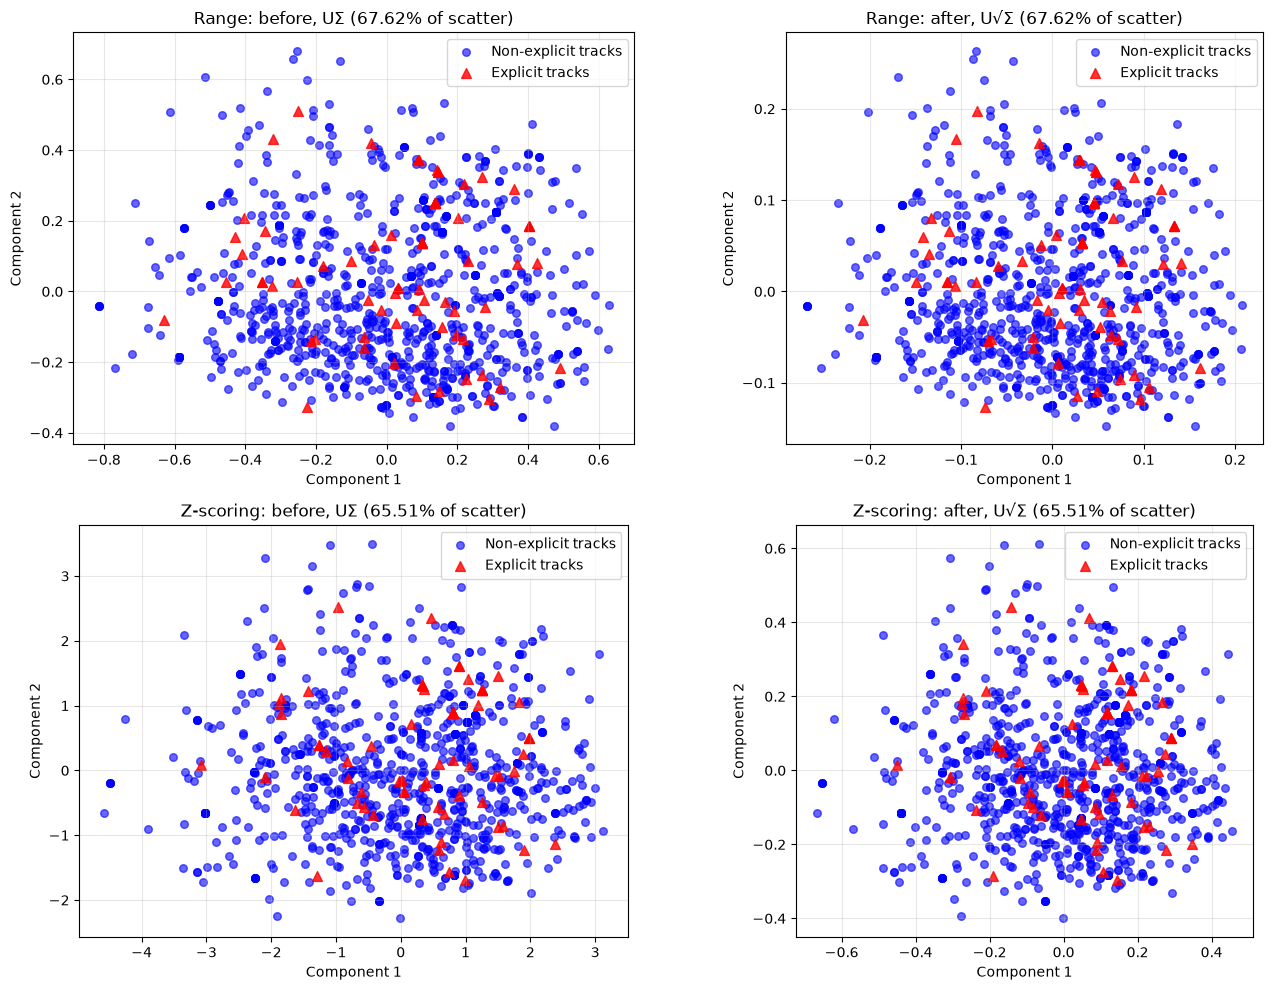

In [10]:
# Computed ordinary PCA scores using the first two singular values.
X_pca_range = U_range[:, :2] @ np.diag(s_range[:2])
X_pca_zscore = U_zscore[:, :2] @ np.diag(s_zscore[:2])

# Distributed the scale between object coordinates F and feature loadings C.
# Multiplied columns of U and V by square roots of singular values.
F_range = U_range[:, :2] @ np.diag(np.sqrt(s_range[:2]))
C_range = Vt_range[:2].T @ np.diag(np.sqrt(s_range[:2]))
F_zscore = U_zscore[:, :2] @ np.diag(np.sqrt(s_zscore[:2]))
C_zscore = Vt_zscore[:2].T @ np.diag(np.sqrt(s_zscore[:2]))

# Summed the contributions of the first two components to the normalized data scatter.
contribution_2d_range = percent_range[:2].sum()
contribution_2d_zscore = percent_zscore[:2].sum()

print(f"Two-dimensional contribution, range normalization: {contribution_2d_range:.2f}%")
print(f"Two-dimensional contribution, z-scoring: {contribution_2d_zscore:.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
points_list = [X_pca_range, F_range, X_pca_zscore, F_zscore]
titles = [
    f'Range: before, UΣ ({contribution_2d_range:.2f}% of scatter)',
    f'Range: after, U√Σ ({contribution_2d_range:.2f}% of scatter)',
    f'Z-scoring: before, UΣ ({contribution_2d_zscore:.2f}% of scatter)',
    f'Z-scoring: after, U√Σ ({contribution_2d_zscore:.2f}% of scatter)'
]


for ax, points, title in zip(axes.flatten(), points_list, titles):
    ax.scatter(points[~explicit_group, 0], points[~explicit_group, 1],
               alpha=0.6, s=30, label='Non-explicit tracks', color='blue', marker='o')
    ax.scatter(points[explicit_group, 0], points[explicit_group, 1],
               alpha=0.8, s=50, label='Explicit tracks', color='red', marker='^')
    ax.set(xlabel='Component 1', ylabel='Component 2', title=title)
    ax.set_aspect('equal', adjustable='box')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Position of the Highlighted Group

The highlighted group is the **74 explicit tracks** (red triangles). Under both normalizations the explicit tracks do **not** form a separate cluster: they are spread over the same area as the non-explicit tracks. They are, however, shifted slightly towards the **upper right**. The group mean on the z-scored plot is **(0.36, 0.32)** against **(−0.03, −0.03)** for the other tracks, that is about 0.24 and 0.31 of the standard deviation of the respective components (1.49 and 1.03). With range normalization the picture is the same (0.044, 0.074 against −0.004, −0.006).

Explicit tracks in this sample have on average higher energy (0.65 vs 0.60), higher loudness (−6.2 vs −7.0 dB) and a faster tempo (134 vs 120 bpm), which explains a move towards positive PC1 (energy and loudness) and positive PC2 (tempo). The `explicit` feature is used only to highlight the group; it is not in the PCA.

The first two components retain **67.62%** of the scatter after range normalization and **65.51%** after z-scoring, so about one third of the information is not visible in these plots. Rescaling (U√Σ instead of UΣ) changes the axis scales while preserving the two-component reconstruction and these contributions.


## A2.4. Interpretation of PC1 and PC2 Using Loadings

Loadings after range normalization:


,PC1,PC2
danceability,1.188,-1.048
energy,1.658,0.172
loudness,0.829,0.039
valence,1.992,-0.273
tempo,0.629,2.340


Loadings after z-scoring:


,PC1,PC2
danceability,2.522,-3.465
energy,3.995,0.957
loudness,3.606,1.111
valence,3.248,-1.097
tempo,1.077,4.152


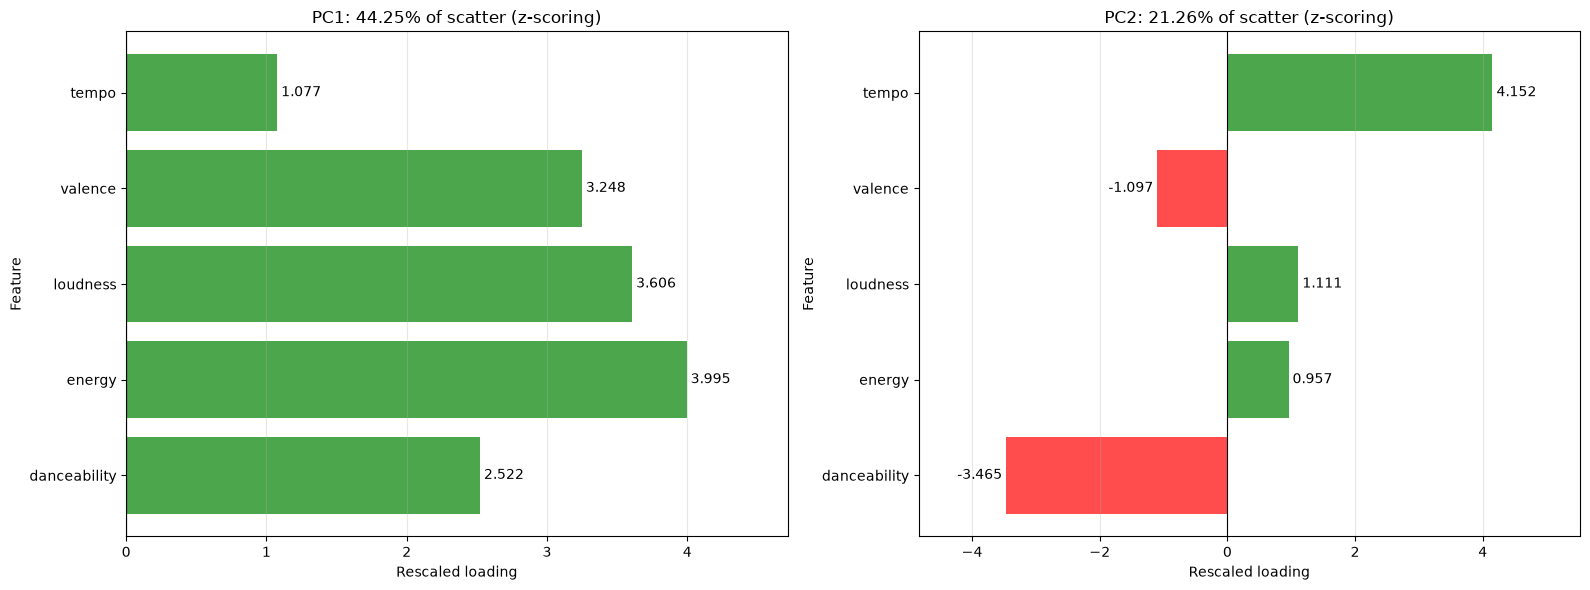

In [11]:
# Created loading tables for both normalization methods.
loadings_range = pd.DataFrame(C_range, index=selected_features, columns=['PC1', 'PC2'])
loadings_zscore = pd.DataFrame(C_zscore, index=selected_features, columns=['PC1', 'PC2'])

# Displayed the loadings rounded to three decimal places.
print("Loadings after range normalization:")
display(loadings_range.round(3))
print("Loadings after z-scoring:")
display(loadings_zscore.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, pc_name in enumerate(['PC1', 'PC2']):
    
    weights = C_zscore[:, i]

    colors = ['green' if w > 0 else 'red' for w in weights]
    axes[i].barh(selected_features, weights, color=colors, alpha=0.7)
    axes[i].set_xlabel('Rescaled loading')
    axes[i].set_ylabel('Feature')
    axes[i].set_title(f'{pc_name}: {percent_zscore[i]:.2f}% of scatter (z-scoring)')
    axes[i].axvline(0, color='black', linewidth=0.8)
    axes[i].grid(True, alpha=0.3, axis='x')
    axes[i].margins(x=0.18)

    for j, weight in enumerate(weights):
        axes[i].text(weight, j, f' {weight:.3f} ', va='center',
                     ha='left' if weight > 0 else 'right', fontsize=10)

plt.tight_layout()
plt.show()

### Interpretation of PC1 and PC2

**Range normalization**

- **PC1 is a general "upbeat and energetic" component.** All loadings are positive: valence (1.992), energy (1.658), danceability (1.188), loudness (0.829) and tempo (0.629). Tracks with high PC1 are happier, more energetic and more danceable. Loudness has a surprisingly small weight (see the discussion of normalization in A2.5).
- **PC2 mainly reflects tempo.** Tempo has the dominant loading (2.340), contrasted with danceability (−1.048). Energy (0.172), loudness (0.039) and valence (−0.273) are close to zero. High PC2 means fast tracks that are less danceable.

**Z-scoring**

- **PC1 is the overall intensity of the sound.** Energy (3.995), loudness (3.606), valence (3.248) and danceability (2.522) all have large positive loadings; tempo has a smaller positive loading (1.077). The largest weights are for energy and loudness, which are the most strongly correlated pair (0.72).
- **PC2 contrasts tempo with danceability.** Tempo has a large positive loading (4.152), danceability a large negative one (−3.465), and valence a smaller negative one (−1.097). Energy (0.957) and loudness (1.111) are small and positive. High PC2 means fast but less danceable (and less cheerful) tracks; low PC2 means danceable but slower tracks.

Loading magnitudes are compared **within each component**. Rescaling preserves the relative weights and signs within each component. These patterns describe associations in the data, not causal effects.

## A2.5. Conventional PCA and Comparison with SVD

In [12]:
# Computed the correlation matrix with division by n.
cov_matrix = np.cov(X_zscore.T) * (n - 1) / n
display(pd.DataFrame(cov_matrix, index=selected_features, columns=selected_features).round(3))

# eigh is used because the correlation matrix is symmetric (it returns real eigenvalues)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
idx = eigenvalues.argsort()[::-1]
eigenvalues_sorted = eigenvalues[idx]
eigenvectors_sorted = eigenvectors[:, idx]
X_pca_manual = X_zscore @ eigenvectors_sorted[:, :2]

# Aligned the first two component signs with SVD.
for k in range(2):
    if np.dot(X_pca_manual[:, k], X_pca_zscore[:, k]) < 0:
        eigenvectors_sorted[:, k] *= -1
        X_pca_manual[:, k] *= -1

# Compared the results with sklearn PCA.
pca_zscore = PCA(n_components=2)
X_pca_sklearn = pca_zscore.fit_transform(X_zscore)
for k in range(2):
    if np.dot(X_pca_sklearn[:, k], X_pca_zscore[:, k]) < 0:
        X_pca_sklearn[:, k] *= -1

explained_var_manual = eigenvalues_sorted / eigenvalues_sorted.sum()
comparison = pd.DataFrame({
    'PC': ['PC1', 'PC2'],
    'SVD: s²/n': s_zscore[:2] ** 2 / n,
    'Conventional PCA: λ': eigenvalues_sorted[:2],
    'sklearn: variance × (n−1)/n': pca_zscore.explained_variance_ * (n - 1) / n,
    'SVD contribution, %': percent_zscore[:2],
    'Conventional PCA contribution, %': 100 * explained_var_manual[:2]
})
display(comparison.round(6))
# Converted correlation-based scores to the balanced factor scale.
s_manual = np.sqrt(n * eigenvalues_sorted[:2])
F_manual = X_pca_manual / np.sqrt(s_manual)


,danceability,energy,loudness,valence,tempo
danceability,1.000,0.283,0.176,0.416,-0.055
energy,0.283,1.000,0.723,0.414,0.166
loudness,0.176,0.723,1.000,0.295,0.075
valence,0.416,0.414,0.295,1.000,0.156
tempo,-0.055,0.166,0.075,0.156,1.000


,PC,SVD: s²/n,Conventional PCA: λ,sklearn: variance × (n−1)/n,"SVD contribution, %","Conventional PCA contribution, %"
0,PC1,2.212726,2.212726,2.212726,44.254514,44.254514
1,PC2,1.062753,1.062753,1.062753,21.255069,21.255069


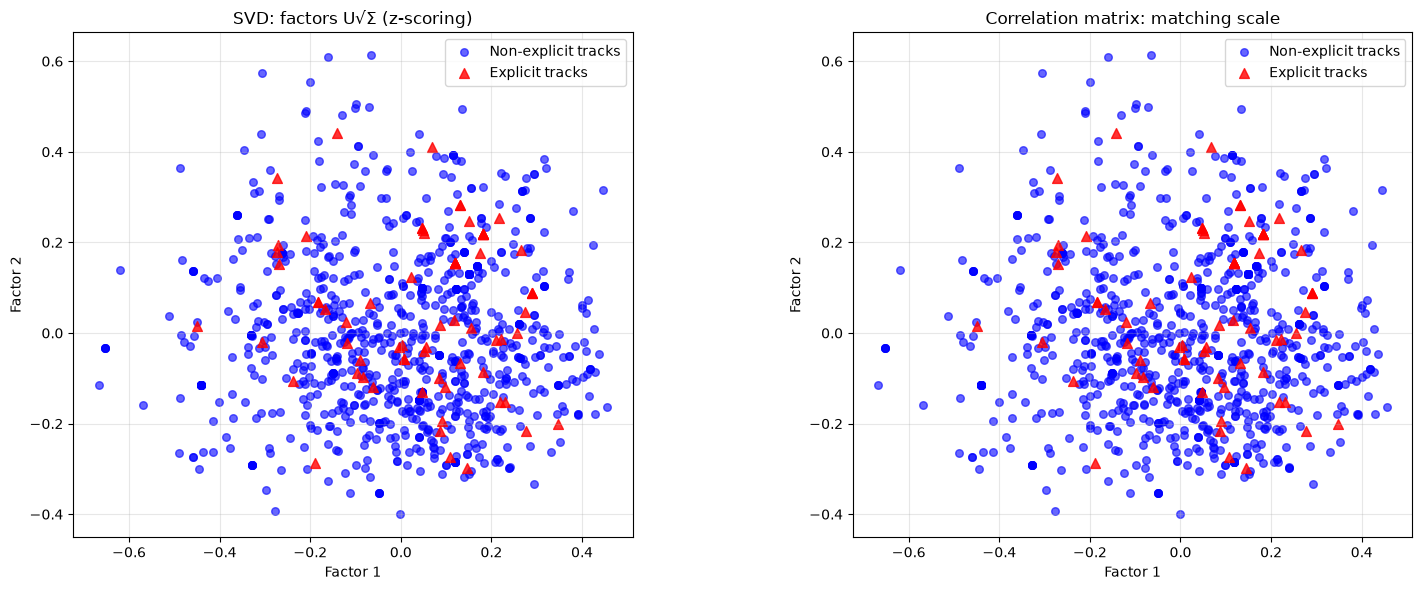

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(F_zscore[~explicit_group, 0], F_zscore[~explicit_group, 1],
                alpha=0.6, s=30, label='Non-explicit tracks', color='blue', marker='o')
axes[0].scatter(F_zscore[explicit_group, 0], F_zscore[explicit_group, 1],
                alpha=0.8, s=50, label='Explicit tracks', color='red', marker='^')
axes[0].set_xlabel('Factor 1')
axes[0].set_ylabel('Factor 2')
axes[0].set_title('SVD: factors U√Σ (z-scoring)')
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(F_manual[~explicit_group, 0], F_manual[~explicit_group, 1],
                alpha=0.6, s=30, label='Non-explicit tracks', color='blue', marker='o')
axes[1].scatter(F_manual[explicit_group, 0], F_manual[explicit_group, 1],
                alpha=0.8, s=50, label='Explicit tracks', color='red', marker='^')
axes[1].set_xlabel('Factor 1')
axes[1].set_ylabel('Factor 2')
axes[1].set_title('Correlation matrix: matching scale')
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Comparison of Methods

After sign alignment, the balanced factors obtained through **SVD** and the **correlation matrix** coincide within numerical precision (differences of order 1e-15). The ordinary scores from the correlation-matrix eigenvectors and from **sklearn PCA** also coincide with the SVD scores (differences of order 1e-14).

Percentage contributions agree across the methods: **44.25%** for PC1 and **21.26%** for PC2. The eigenvalues of the correlation matrix (2.2127 and 1.0628) equal s²/n from the SVD. This is expected: for z-scored data the SVD and the eigen-decomposition of the correlation matrix are two ways of computing the same thing.

### Choice of Normalization

I choose **z-scoring** for these data, for three reasons.

1. **Range normalization depends on extreme values.** Loudness has a few very quiet tracks (the minimum is −20.6 dB), which stretch its range to 19.5 dB, about 7.6 standard deviations. The other features have ranges of only 4.4–5.2 standard deviations. As a result, loudness contributes only **8.97%** of the range-normalized scatter, whereas valence contributes 27.13%, tempo 22.94%, energy 21.67% and danceability 19.29%. A handful of outliers therefore reduce the weight of a whole feature. This is why loudness has such a small loading on PC1 under range normalization, although it is strongly related to energy.
2. **Z-scoring treats all features equally.** Each standardized feature has a variance of 1 and contributes exactly 20% of the scatter, so the components reflect the correlation structure rather than the accidental extreme values. Under z-scoring PC1 correctly shows energy and loudness as the leading, strongly related features.
3. **The 2D contribution does not decide.** The first two components retain 67.62% (range) and 65.51% (z-scoring) of their own tables' scatter; this small difference is partly due to the under-weighted loudness, and cannot be used alone to say that range normalization is better.

Range normalization could be preferred when outliers are absent and the original ratios between feature spreads are meaningful; it is not the case here.

# A2.6. Hidden Ranking Factor on a 0–100 Scale

In [14]:
# Rescaled each feature to 0–100.
X_rank = 100 * (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

# Computed the first factor of the ranking-normalized table without centering.
U_rank, s_rank, Vt_rank = np.linalg.svd(X_rank, full_matrices=False)
if Vt_rank[0].sum() < 0:
    U_rank[:, 0] *= -1
    Vt_rank[0] *= -1

factor_raw = U_rank[:, 0] * s_rank[0]
hidden_factor = 100 * (factor_raw - factor_raw.min()) / (factor_raw.max() - factor_raw.min())

rank_loadings = pd.Series(Vt_rank[0], index=selected_features, name='Factor weight')
ranking_df = pd.DataFrame(X_rank, index=df.index, columns=selected_features)
ranking_df['hidden_factor_0_100'] = hidden_factor
ranking_df['explicit'] = df['explicit']
ranking_df['track_name'] = df['track_name']

print("Hidden factor loadings:")
display(rank_loadings.round(3))
print("Features and hidden factor on a 0–100 scale:")
display(ranking_df.head(10).round(2))

rank_scatter = np.sum(X_rank ** 2)
rank_contribution = 100 * s_rank[0] ** 2 / rank_scatter
print(f"First factor contribution to the ranking-normalized table scatter: {rank_contribution:.2f}%")
print(f"Hidden factor range: {hidden_factor.min():.2f}–{hidden_factor.max():.2f}")

print("Five observations with the lowest scores (unique track names):")
display(ranking_df.drop_duplicates("track_name").nsmallest(5, 'hidden_factor_0_100').round(2))
print("Five observations with the highest scores (unique track names):")
display(ranking_df.drop_duplicates("track_name").nlargest(5, 'hidden_factor_0_100').round(2))


Hidden factor loadings:


danceability    0.468
energy          0.452
loudness        0.542
valence         0.406
tempo           0.344
Name: Factor weight, dtype: float64

Features and hidden factor on a 0–100 scale:


,danceability,energy,loudness,valence,tempo,hidden_factor_0_100,explicit,track_name
0,43.26,70.64,75.27,31.77,77.74,62.87,False,Blinding Lights
1,46.21,74.66,65.41,35.96,91.79,66.04,False,Mann Mera
2,91.85,48.97,72.32,98.17,39.93,81.16,False,Summer High
3,74.02,66.06,77.34,29.19,41.28,62.77,True,Under The Influence
4,66.43,54.24,69.74,48.10,87.86,70.49,True,Starboy
5,82.87,52.52,69.66,28.55,29.12,55.11,False,Insane
6,72.75,57.80,59.55,3.22,29.83,42.19,False,Akhiyaan
7,90.03,50.92,75.67,49.07,28.50,65.24,False,Daku
8,64.04,32.80,48.33,62.18,16.29,40.61,False,Jhoom - R&B Mix
9,79.49,61.35,72.83,84.42,23.11,73.01,False,Na Ja


First factor contribution to the ranking-normalized table scatter: 93.46%
Hidden factor range: 0.00–100.00
Five observations with the lowest scores (unique track names):


,danceability,energy,loudness,valence,tempo,hidden_factor_0_100,explicit,track_name
887,23.46,0.00,38.25,14.37,23.70,0.00,False,Blue Banisters
875,36.66,0.57,49.40,12.65,9.90,5.09,False,Happiness is a butterfly
767,8.71,25.23,60.21,14.69,0.00,6.08,False,Mujhe Peene Do
684,28.93,13.99,28.08,8.67,56.96,9.04,False,TV
968,53.65,13.30,0.00,26.61,54.10,10.72,False,Zara Zara - MTV Unwind


Five observations with the highest scores (unique track names):


,danceability,energy,loudness,valence,tempo,hidden_factor_0_100,explicit,track_name
426,61.52,89.22,100.00,78.30,83.84,100.00,False,Bad Boy (feat. Luana Kiara)
680,78.51,95.64,91.22,65.40,78.44,99.28,False,Expert Jatt
656,82.58,73.28,89.71,93.23,70.29,98.89,False,Libaas
530,81.04,94.95,83.27,93.45,51.43,98.30,False,Thaar Maar Thakkar Maar
192,92.70,80.16,84.84,100.00,44.66,98.27,False,There's Nothing Holdin' Me Back


Hidden factor by group (explicit = True / False):


,count,mean,median,min,max
explicit,,,,,
False,926,58.31,60.39,0.00,100.00
True,74,64.27,70.29,13.48,89.75


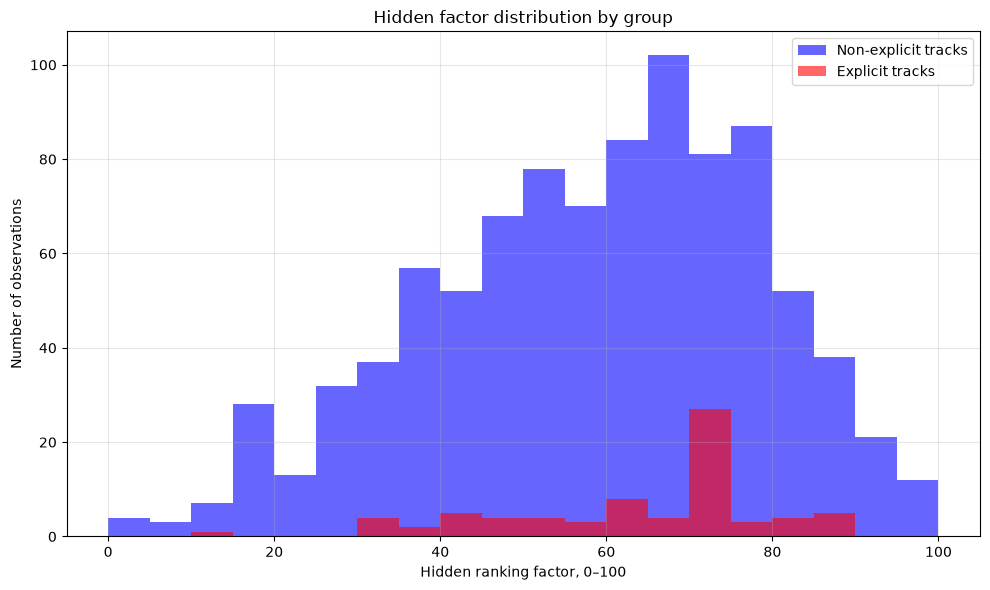

In [15]:
print("Hidden factor by group (explicit = True / False):")
display(ranking_df.groupby('explicit')['hidden_factor_0_100'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2))

plt.figure(figsize=(10, 6))
bins = np.linspace(0, 100, 21)
plt.hist(hidden_factor[~explicit_group], bins=bins, alpha=0.6, label='Non-explicit tracks', color='blue')
plt.hist(hidden_factor[explicit_group], bins=bins, alpha=0.6, label='Explicit tracks', color='red')
plt.xlabel('Hidden ranking factor, 0–100')
plt.ylabel('Number of observations')
plt.title('Hidden factor distribution by group')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of the Hidden Ranking Factor

All loadings are positive: **loudness 0.542**, **danceability 0.468**, **energy 0.452**, **valence 0.406**, and **tempo 0.344**. A higher score represents a higher overall level of these features, that is a **louder, more energetic, more danceable, more cheerful and faster track**. The hidden factor can be read as the **overall energetic/upbeat intensity** of the sound, with loudness, danceability and energy contributing most.

The first factor accounts for **93.46%** of the uncentered ranking-normalized table's quadratic scatter about zero. This percentage is high because all ranking-normalized values are positive, so the first uncentered component mostly describes the common level of the features. It uses a different transformation and reference point from those in A2.2–A2.3, so it should not be compared with the percentages there.

The mean score is **64.27 for explicit tracks** and **58.31 for non-explicit tracks** (medians 70.29 and 60.39). This is a descriptive group difference: explicit tracks tend to sound more intense. The `explicit` feature is excluded from the factor calculation and the groups overlap strongly (explicit tracks range from 13.48 to 89.75).

The endpoints **0 and 100** correspond to the observations with the lowest and highest factor values in this sample. The lowest score belongs to *Blue Banisters* (it has the lowest energy of all tracks, and low valence and danceability), and the highest to *Bad Boy (feat. Luana Kiara)* (the loudest track, with high energy and valence). Note that some songs appear several times in the file (for instance, *Blue Banisters* is listed four times with identical features), so the lists above show unique track names. The score is a composite measure of the selected features.